In [2]:
# Colab/py deps (TensorFlow is already on Colab; scikit-learn + matplotlib are standard)
import os, re, json, math, joblib, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from pathlib import Path
from typing import Tuple

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor

import matplotlib.pyplot as plt


In [3]:
DATA_DIR = Path("prime_dataset")  # change if you put it elsewhere

def read_csv_guess_header(fp: Path, default_cols=("input","output")) -> pd.DataFrame:
    """Reads csv whether header exists or not. Ensures columns are named input,output."""
    try:
        df = pd.read_csv(fp)
        # If it didn't detect headers (or wrong names), fix them
        if df.shape[1] == 2 and set(map(str.lower, df.columns)) != set(default_cols):
            df.columns = default_cols
    except Exception:
        df = pd.read_csv(fp, header=None, names=default_cols)
    # strip whitespace
    for c in df.columns:
        if df[c].dtype == object:
            df[c] = df[c].astype(str).str.strip()
    return df

# Load all that exist (train/val/test/complete)
frames = {}
for name in ["train.csv", "validation.csv", "val.csv", "test.csv", "complete_dataset.csv"]:
    fp = DATA_DIR / name
    if fp.exists():
        frames[name] = read_csv_guess_header(fp)
    print("read success" if fp.exists() else "not found:", name, frames.get(name, None).shape if name in frames else None)

frames


read success train.csv (6714, 2)
read success validation.csv (1438, 2)
not found: val.csv None
read success test.csv (1440, 2)
read success complete_dataset.csv (9592, 2)


{'train.csv':       input  output
 0      2125   18553
 1      4025   38119
 2      3795   35677
 3      6526   65327
 4      3474   32371
 ...     ...     ...
 6709   4521   43321
 6710   2365   21019
 6711   2678   24077
 6712   6708   67343
 6713   5801   57193
 
 [6714 rows x 2 columns],
 'validation.csv':       input  output
 0      1495   12517
 1      5615   55259
 2      4218   40153
 3      1347   11117
 4      3865   36467
 ...     ...     ...
 1433    775    5881
 1434   7445   75571
 1435   7579   77141
 1436   5278   51577
 1437   3850   36277
 
 [1438 rows x 2 columns],
 'test.csv':       input  output
 0      2751   24889
 1      9466   98573
 2      1441   12037
 3      7010   70793
 4      3429   31963
 ...     ...     ...
 1435   2604   23357
 1436   8854   91577
 1437   6630   66499
 1438   1633   13807
 1439    480    3413
 
 [1440 rows x 2 columns],
 'complete_dataset.csv':       input  output
 0         1       2
 1         2       3
 2         3       5
 3       

In [4]:
def parse_scalar_to_features(x):
    """
    Convert input to a single feature (real number).
    Returns [float(x)] as a 1D feature array.
    """
    try:
        return [float(x)]
    except:
        raise ValueError(f"Cannot parse value '{x}' as a real number.")

def df_to_Xy(df: pd.DataFrame) -> Tuple[np.ndarray, np.ndarray]:
    X = np.array([[float(v)] for v in df["input"].values])  # Shape (n, 1)
    y = np.array([float(v) for v in df["output"].values])   # Shape (n,)
    return X, y

In [5]:
# Priority: use provided splits; else split complete_dataset
if "train.csv" in frames and ("validation.csv" in frames or "val.csv" in frames) and "test.csv" in frames:
    train_df = frames["train.csv"]
    val_df   = frames.get("validation.csv", frames.get("val.csv"))
    test_df  = frames["test.csv"]
elif "complete_dataset.csv" in frames:
    full_df = frames["complete_dataset.csv"]
    # Keep 15% test, 15% val by default (change sizes as needed)
    temp_df, test_df = train_test_split(full_df, test_size=0.15, random_state=42)
    train_df, val_df = train_test_split(temp_df, test_size=0.15, random_state=42)
else:
    raise RuntimeError("Please provide either train/val/test CSVs or complete_dataset.csv.")

for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, df.shape)
    display(df.head())

X_train, y_train = df_to_Xy(train_df)
X_val,   y_val   = df_to_Xy(val_df)
X_test,  y_test  = df_to_Xy(test_df)

print("Shapes:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:",   X_val.shape,   "y_val:",   y_val.shape)
print("X_test:",  X_test.shape,  "y_test:",  y_test.shape)

train (6714, 2)


,input,output
0,2125,18553
1,4025,38119
2,3795,35677
3,6526,65327
4,3474,32371


val (1438, 2)


,input,output
0,1495,12517
1,5615,55259
2,4218,40153
3,1347,11117
4,3865,36467


test (1440, 2)


,input,output
0,2751,24889
1,9466,98573
2,1441,12037
3,7010,70793
4,3429,31963


Shapes:
X_train: (6714, 1) y_train: (6714,)
X_val: (1438, 1) y_val: (1438,)
X_test: (1440, 1) y_test: (1440,)


In [6]:
def evaluate(model, Xtr, ytr, Xva, yva, name):
    model.fit(Xtr, ytr)
    pred = model.predict(Xva)
    mae  = mean_absolute_error(yva, pred)
    rmse = np.sqrt(mean_squared_error(yva, pred))  # Fix: use sqrt instead of squared=False
    r2   = r2_score(yva, pred)
    return {"name": name, "model": model, "MAE": mae, "RMSE": rmse, "R2": r2}

results = []

# 5a) Polynomial Regression (degree=3 to start; increase if needed)
poly_deg = 3
poly_model = Pipeline([
    ("scaler_x", StandardScaler()),
    ("poly", PolynomialFeatures(degree=poly_deg, include_bias=False)),
    ("lr", LinearRegression())
])
results.append(evaluate(poly_model, X_train, y_train, X_val, y_val, f"Poly(d={poly_deg})"))

# 5b) Random Forest (quick, robust)
rf_model = Pipeline([
    ("scaler_x", StandardScaler(with_mean=True, with_std=True)),  # RF doesn't need scaling, but harmless
    ("rf", RandomForestRegressor(n_estimators=300, max_depth=None, random_state=42, n_jobs=-1))
])
results.append(evaluate(rf_model, X_train, y_train, X_val, y_val, "RandomForest"))

# 5c) Sklearn MLP (small + early stopping via tol)
mlp_model = Pipeline([
    ("scaler_x", StandardScaler()),
    ("mlp", MLPRegressor(hidden_layer_sizes=(128,64),
                         activation="relu",
                         solver="adam",
                         alpha=1e-4,
                         learning_rate_init=1e-3,
                         max_iter=1000,
                         early_stopping=True,
                         n_iter_no_change=25,
                         random_state=42))
])
results.append(evaluate(mlp_model, X_train, y_train, X_val, y_val, "MLPRegressor(128,64)"))

# 5d) Linear baseline (sanity check)
lin_model = Pipeline([
    ("scaler_x", StandardScaler()),
    ("lr", LinearRegression())
])
results.append(evaluate(lin_model, X_train, y_train, X_val, y_val, "LinearRegression"))

pd.DataFrame(results)[["name","MAE","RMSE","R2"]].sort_values("RMSE")

,name,MAE,RMSE,R2
1,RandomForest,7.673558,10.538883,1.000000
0,Poly(d=3),84.297927,111.734673,0.999986
2,"MLPRegressor(128,64)",608.715673,897.765703,0.999072
3,LinearRegression,863.685673,1042.056335,0.998750


In [7]:
# Pick best by RMSE
df_res = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
best = df_res.loc[0, "model"]
best_name = df_res.loc[0, "name"]
print("Best on val:", best_name)

# Retrain on train+val
X_tv = np.vstack([X_train, X_val])
y_tv = np.concatenate([y_train, y_val])  # Use concatenate for 1D arrays
best.fit(X_tv, y_tv)

# Test
pred_test = best.predict(X_test)
mae  = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
r2   = r2_score(y_test, pred_test)
print(f"TEST: MAE={mae:.6f}  RMSE={rmse:.6f}  R2={r2:.6f}")

# Save
ART_DIR = Path("blackbox_artifacts")
ART_DIR.mkdir(exist_ok=True, parents=True)

joblib.dump(best, ART_DIR / "best_model.joblib")
meta = {"best_name": best_name, "test": {"MAE": float(mae), "RMSE": float(rmse), "R2": float(r2)}}
with open(ART_DIR / "meta.json","w") as f:
    json.dump(meta, f, indent=2)

print("Saved:", list(ART_DIR.iterdir()))

Best on val: RandomForest
TEST: MAE=6.531426  RMSE=9.078804  R2=1.000000
Saved: [WindowsPath('blackbox_artifacts/best_model.joblib'), WindowsPath('blackbox_artifacts/meta.json')]
TEST: MAE=6.531426  RMSE=9.078804  R2=1.000000
Saved: [WindowsPath('blackbox_artifacts/best_model.joblib'), WindowsPath('blackbox_artifacts/meta.json')]


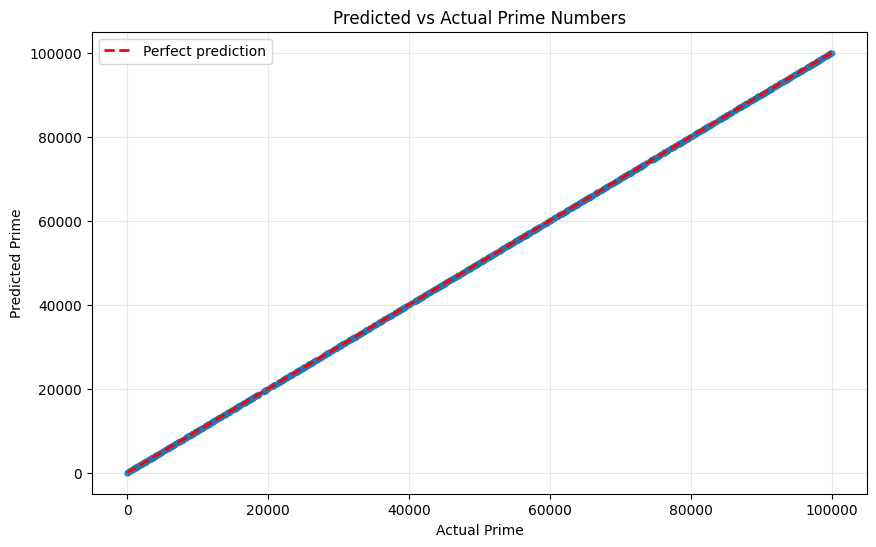

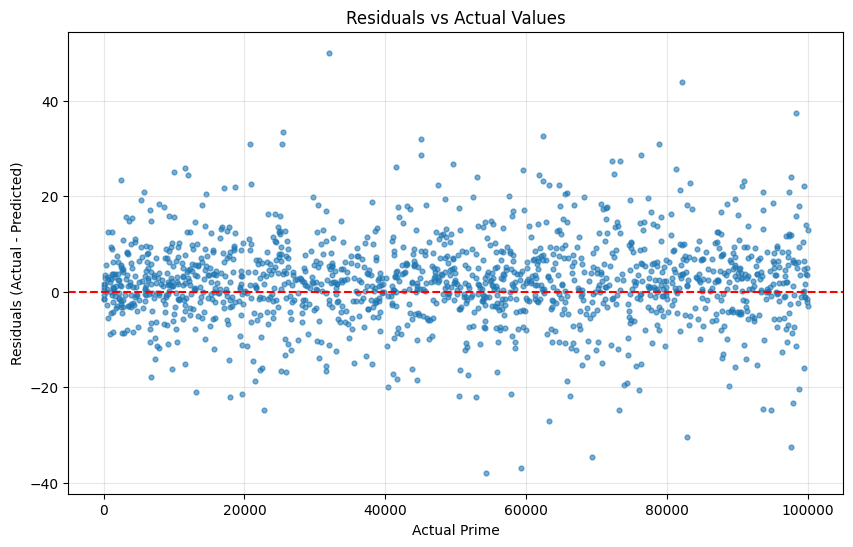

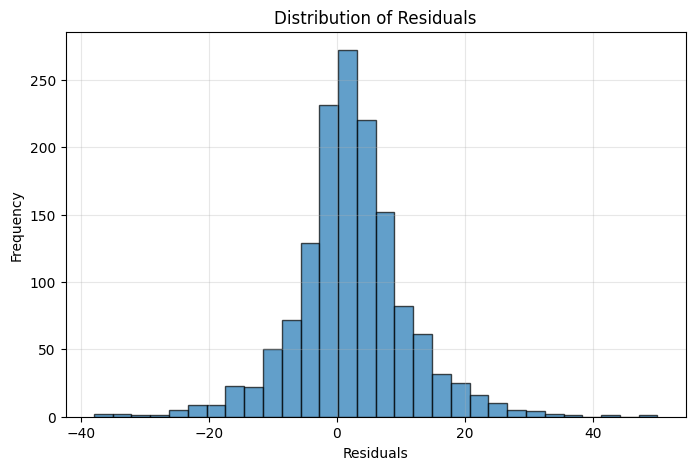

In [8]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, pred_test, s=12, alpha=0.6)
plt.xlabel("Actual Prime")
plt.ylabel("Predicted Prime")
plt.title("Predicted vs Actual Prime Numbers")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect prediction')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Residuals plot
resid = y_test - pred_test
plt.figure(figsize=(10, 6))
plt.scatter(y_test, resid, s=12, alpha=0.6)
plt.xlabel("Actual Prime")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residuals vs Actual Values")
plt.axhline(y=0, color='r', linestyle='--')
plt.grid(True, alpha=0.3)
plt.show()

# Histogram of residuals
plt.figure(figsize=(8, 5))
plt.hist(resid, bins=30, alpha=0.7, edgecolor='black')
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.grid(True, alpha=0.3)
plt.show()

Evaluation Results:
MAE (Mean Absolute Error): 24287.24
MAPE (Mean Absolute Percentage Error): 0.0124
CSV saved to: \mnt\data\test_data_eval.csv
Plot saved to: \mnt\data\actual_vs_predicted.png

First few results:
        n  nth_prime          f(n)         error     abs_error
0  100001    1299721  1.284931e+06 -14790.079674  14790.079674
1  110000    1441049  1.424263e+06 -16785.863233  16785.863233
2  120000    1583539  1.564548e+06 -18991.300068  18991.300068
3  130000    1726943  1.705692e+06 -21250.911375  21250.911375
4  140000    1870667  1.847630e+06 -23037.175401  23037.175401


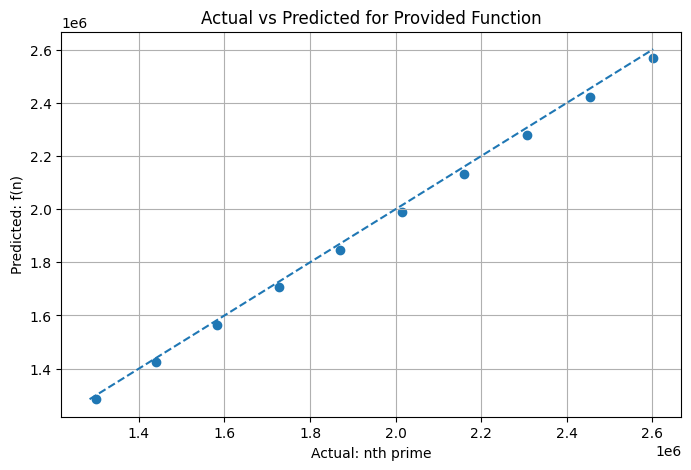

In [2]:
# Display results
print("Evaluation Results:")
print(f"MAE (Mean Absolute Error): {mae:.2f}")
print(f"MAPE (Mean Absolute Percentage Error): {mape:.4f}")
print(f"CSV saved to: {csv_path}")
print(f"Plot saved to: {plot_path}")
print("\nFirst few results:")
print(df.head())

# Show the plot
plt.figure(figsize=(8, 5))
plt.scatter(df["nth_prime"].values, df["f(n)"].values)
minv = float(min(df["nth_prime"].min(), np.nanmin(df["f(n)"])))
maxv = float(max(df["nth_prime"].max(), np.nanmax(df["f(n)"])))
plt.plot([minv, maxv], [minv, maxv], linestyle='--')  # 45-degree line
plt.xlabel("Actual: nth prime")
plt.ylabel("Predicted: f(n)")
plt.title("Actual vs Predicted for Provided Function")
plt.grid(True)
plt.show()

In [10]:
# Load once per session
best_loaded = joblib.load(ART_DIR / "best_model.joblib")

def predict_nth_prime(n):
    """
    Predict the nth prime number.
    
    Parameters:
    n: int or str - the index of the prime number to predict
    
    Returns:
    float - predicted nth prime number
    """
    try:
        n_val = float(n)
        feats = np.array([[n_val]])  # shape (1, 1)
        pred = best_loaded.predict(feats)[0]  # single value
        return float(pred)
    except Exception as e:
        raise ValueError(f"Cannot predict for input '{n}': {e}")

# EXAMPLES
print(f"1th prime (predicted): {predict_nth_prime(1):.2f}")
print(f"22nd prime (predicted): {predict_nth_prime(22):.2f}")
print(f"500th prime (predicted): {predict_nth_prime(500):.2f}")
print(f"1000th prime (predicted): {predict_nth_prime(9592):.2f}")

1th prime (predicted): 2.97
22nd prime (predicted): 77.76
500th prime (predicted): 3568.78
1000th prime (predicted): 99978.02


In [ ]:
# Also show a small preview table
print("\nDataFrame preview:")
print(df.head(10))  # Show first 10 rows

mae, mape, str(csv_path), str(plot_path)

ModuleNotFoundError: No module named 'caas_jupyter_tools'